In [1]:
import pandas as pd
import numpy as np

acs_need = pd.read_csv("Agg Data FINAL/Panhandle_Community_Need_Index.csv")
tracts = pd.read_csv("Agg Data FINAL/Panhandle_Census_Tracts.csv")
facilities = pd.read_excel("Agg Data FINAL/Panhandle_All_Facilities.xlsx")

print(acs_need.shape)
print(tracts.shape)
print(facilities.shape)

(27, 12)
(27, 4)
(17, 7)


In [2]:
print(tracts.columns)
print(facilities.columns)

Index(['County', 'Tract_GEOID', 'Latitude', 'Longitude'], dtype='object')
Index(['Facility_Name', 'County', 'City', 'Address', 'Longitude', 'Latitude',
       'Facility_Type'],
      dtype='object')


Note that these are straight line distances!

In [3]:

import numpy as np
from math import radians, sin, cos, sqrt, atan2

# calculating distance between two locations in miles
def calculate_distance(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(radians, [lat1, lon1, lat2, lon2])
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = sin(dlat/2)**2 + cos(lat1) * cos(lat2) * sin(dlon/2)**2
    c = 2 * atan2(sqrt(a), sqrt(1-a))
    return 3958.8 * c

# creating a facility list without Sand Canyon
facilities_without = facilities[
    facilities["Facility_Name"] != "Sand Canyon Health Center"]

# find the nearest facility for each tract
nearest_with = []
nearest_without = []

for i, tract in tracts.iterrows():
    distances_with = []
    distances_without = []

    # distances WITH Sand Canyon
    for j, facility in facilities.iterrows():
        distance = calculate_distance(
            tract["Latitude"],
            tract["Longitude"],
            facility["Latitude"],
            facility["Longitude"])
        distances_with.append(distance)

    # distances WITHOUT Sand Canyon
    for j, facility in facilities_without.iterrows():
        distance = calculate_distance(
            tract["Latitude"],
            tract["Longitude"],
            facility["Latitude"],
            facility["Longitude"])
        distances_without.append(distance)

    nearest_with.append(min(distances_with))
    nearest_without.append(min(distances_without))

# adding distances to the tract data
tracts["Distance_With_Sand_Canyon"] = nearest_with
tracts["Distance_Without_Sand_Canyon"] = nearest_without

# calculating the difference between scenarios
tracts["Distance_Increase"] = (
    tracts["Distance_Without_Sand_Canyon"] - tracts["Distance_With_Sand_Canyon"])

display(tracts[[
    "County",
    "Tract_GEOID",
    "Distance_With_Sand_Canyon",
    "Distance_Without_Sand_Canyon",
    "Distance_Increase"]])

,County,Tract_GEOID,Distance_With_Sand_Canyon,Distance_Without_Sand_Canyon,Distance_Increase
0,BANNER,31007954000,21.233244,21.233244,0.0
1,BOX BUTTE,31013951100,5.860447,5.860447,0.0
2,BOX BUTTE,31013951200,5.654517,5.654517,0.0
3,BOX BUTTE,31013951300,5.731869,5.731869,0.0
4,CHEYENNE,31033954800,6.236515,6.236515,0.0
5,CHEYENNE,31033954900,2.576288,2.576288,0.0
6,CHEYENNE,31033955000,0.565491,0.565491,0.0
7,DAWES,31045950600,10.573570,10.573570,0.0
8,DAWES,31045950700,2.324525,2.324525,0.0
9,DEUEL,31049955400,13.819561,13.819561,0.0


In [4]:
tracts.to_csv("Agg Data FINAL/Panhandle_Tract_Facility_Distances.csv",index=False)

In [5]:
display(facilities[facilities["Facility_Name"] == "Sand Canyon Health Center"])

,Facility_Name,County,City,Address,Longitude,Latitude,Facility_Type
16,Sand Canyon Health Center,BOX BUTTE,HEMINGFORD,"800 Box Butte Ave, Hemingford, NE 69348",-103.073091,42.32187,Sand Canyon


In [6]:
for i, tract in tracts[tracts["County"] == "BOX BUTTE"].iterrows():
    distance = calculate_distance(
        tract["Latitude"],
        tract["Longitude"],
        42.32187009111592,
        -103.07309104622846)
    print(tract["Tract_GEOID"], distance)

31013951100 5.9455775039485355
31013951200 20.105519243234617
31013951300 23.344397451788527


In [7]:
print(tracts[["County","Tract_GEOID","Distance_With_Sand_Canyon","Distance_Without_Sand_Canyon","Distance_Increase"]].query("County == 'BOX BUTTE'"))

      County  Tract_GEOID  Distance_With_Sand_Canyon  \
1  BOX BUTTE  31013951100                   5.860447   
2  BOX BUTTE  31013951200                   5.654517   
3  BOX BUTTE  31013951300                   5.731869   

   Distance_Without_Sand_Canyon  Distance_Increase  
1                      5.860447                0.0  
2                      5.654517                0.0  
3                      5.731869                0.0  


In [8]:
# checking whether Sand Canyon is the nearest facility to any tract ... news flash... not good lol
for i, tract in tracts.iterrows():

    distance_to_sand_canyon = calculate_distance(
        tract["Latitude"],
        tract["Longitude"],
        42.32187009111592,
        -103.07309104622846)

    if distance_to_sand_canyon < tract["Distance_With_Sand_Canyon"]:
        print(tract["County"], tract["Tract_GEOID"],
              round(distance_to_sand_canyon, 2), "miles")

In [9]:
# creating matching tract descriptions using the GEOIDs
tracts["Tract_Number"] = (tracts["Tract_GEOID"].astype(str).str[-6:].astype(int) // 100)
tracts["Tract"] = ("Census Tract " + tracts["Tract_Number"].astype(str) + "; " + tracts["County"].str.title() + " County; Nebraska")

# combining community need and facility distances
project_data = acs_need.merge(tracts[["Tract","Tract_GEOID","Distance_With_Sand_Canyon","Distance_Without_Sand_Canyon","Distance_Increase"]],on="Tract",how="left")

print(project_data.shape)
print(project_data["Distance_With_Sand_Canyon"].isna().sum())
print(project_data["Distance_Without_Sand_Canyon"].isna().sum())

display(project_data[["Tract","Community_Need_Index","Distance_With_Sand_Canyon","Distance_Without_Sand_Canyon","Distance_Increase"]])

(27, 16)
0
0


,Tract,Community_Need_Index,Distance_With_Sand_Canyon,Distance_Without_Sand_Canyon,Distance_Increase
0,Census Tract 9545; Kimball County; Nebraska,0.877977,3.124918,3.124918,0.0
1,Census Tract 9537; Scotts Bluff County; Nebraska,0.821437,1.430032,1.430032,0.0
2,Census Tract 9531; Scotts Bluff County; Nebraska,0.683019,3.248792,3.248792,0.0
3,Census Tract 9535; Scotts Bluff County; Nebraska,0.650663,1.637908,1.637908,0.0
4,Census Tract 9521; Garden County; Nebraska,0.534964,15.436605,15.436605,0.0
5,Census Tract 9516; Sheridan County; Nebraska,0.422660,2.281271,2.281271,0.0
6,Census Tract 9517; Sheridan County; Nebraska,0.182884,18.919640,18.919640,0.0
7,Census Tract 9538; Scotts Bluff County; Nebraska,0.165542,2.255951,2.255951,0.0
8,Census Tract 9554; Deuel County; Nebraska,0.086290,13.819561,13.819561,0.0
9,Census Tract 9550; Cheyenne County; Nebraska,0.019821,0.565491,0.565491,0.0


In [10]:
project_data.to_csv("Agg Data FINAL/Panhandle_Need_and_Access.csv",index=False)

In [11]:
primary_care = pd.ExcelFile("Agg Data FINAL/Final_HRSA_Primary_Care.xlsx")
mental_health = pd.ExcelFile("Agg Data FINAL/Final HRSA Mental Health.xlsx")

print("Primary Care Sheets:", primary_care.sheet_names)
print("Mental Health Sheets:", mental_health.sheet_names)

Primary Care Sheets: ['SHORTAGE_AREA_HP_DETAIL_VX', 'Data Dictionary', 'Designation_Details', 'County_Summary', 'Read_Me']
Mental Health Sheets: ['SHORTAGE_AREA_HP_DETAIL_VX', 'Data Dictionary', 'Designation_Details', 'County_Summary', 'Read_Me']


In [12]:
#loading the county summary and designation details
pc_county = pd.read_excel("Agg Data FINAL/Final_HRSA_Primary_Care.xlsx",sheet_name="County_Summary")
mh_county = pd.read_excel("Agg Data FINAL/Final HRSA Mental Health.xlsx",sheet_name="County_Summary")
pc_details = pd.read_excel("Agg Data FINAL/Final_HRSA_Primary_Care.xlsx",sheet_name="Designation_Details")
mh_details = pd.read_excel("Agg Data FINAL/Final HRSA Mental Health.xlsx",sheet_name="Designation_Details")


print("PRIMARY CARE")
print(pc_county.columns.tolist())
display(pc_county.head())
print("MENTAL HEALTH")
print(mh_county.columns.tolist())
display(mh_county.head())

PRIMARY CARE
['County', 'Active unique HPSAs', 'Active geographic', 'Active population', 'Active facility', 'Withdrawn unique HPSAs', 'Interpretation note']


,County,Active unique HPSAs,Active geographic,Active population,Active facility,Withdrawn unique HPSAs,Interpretation note
0,Banner,1,1,0,0,0,Designation applies to specified geography/pop...
1,Box Butte,1,0,1,0,1,Designation applies to specified geography/pop...
2,Cheyenne,2,0,1,1,0,Designation applies to specified geography/pop...
3,Dawes,2,0,1,1,2,Designation applies to specified geography/pop...
4,Deuel,1,1,0,0,3,Designation applies to specified geography/pop...


MENTAL HEALTH
['County', 'Designated HPSAs (unique IDs)', 'Withdrawn HPSAs (unique IDs)', 'All unique HPSA IDs', 'Source component records', 'Designation types (active)']


,County,Designated HPSAs (unique IDs),Withdrawn HPSAs (unique IDs),All unique HPSA IDs,Source component records,Designation types (active)
0,Banner,1,0,1,1,Geographic HPSA
1,Box Butte,1,0,1,1,Geographic HPSA
2,Cheyenne,2,0,2,2,Geographic HPSA; Rural Health Clinic
3,Dawes,2,1,3,3,Geographic HPSA; Rural Health Clinic
4,Deuel,1,0,1,1,Geographic HPSA


In [13]:
print("PRIMARY CARE DETAILS")
print(pc_details.columns.tolist())
display(pc_details.head(10))
print("MENTAL HEALTH DETAILS")
print(mh_details.columns.tolist())
display(mh_details.head(10))

PRIMARY CARE DETAILS
['County', 'HPSA Name', 'HPSA ID', 'Designation Type', 'Status', 'HPSA Score', 'Designation Date (Excel serial)', 'Last Update (Excel serial)', 'Component Name', 'Component Type', 'Population Type', 'Designation Population', 'Shortage', 'Provider FTE', 'Source County', 'Primary State', 'First occurrence of county + HPSA ID + status (1/0)', 'Category (Geographic / Population / Facility)', 'Original HRSA source row']


,County,HPSA Name,HPSA ID,Designation Type,Status,HPSA Score,Designation Date (Excel serial),Last Update (Excel serial),Component Name,Component Type,Population Type,Designation Population,Shortage,Provider FTE,Source County,Primary State,First occurrence of county + HPSA ID + status (1/0),Category (Geographic / Population / Facility),Original HRSA source row
0,Sheridan,GORDON CLINIC,13199931B4,Rural Health Clinic,Designated,18,41080,45754,GORDON CLINIC,Unknown,Rural Health Clinic,15718.0,NaN,NaN,"Sheridan County, NE",NE,1,Facility,34168
1,Kimball,KIMBALL COUNTY HOSPITAL CLINIC,13199931B3,Rural Health Clinic,Withdrawn,16,41080,43867,KIMBALL COUNTY HOSPITAL CLINIC,Unknown,Rural Health Clinic,5476.0,NaN,NaN,"Kimball County, NE",NE,1,Facility,34169
2,Deuel,Low Income-Sedgwick/Deuel(CO/NE),13199931B2,HPSA Population,Withdrawn,14,40899,40899,Deuel,Single County,Low Income Population HPSA,1876.0,0.33,0.3,"Deuel County, NE",NE,1,Population,34171
3,Sioux,Crawford,1319993103,Geographic HPSA,Withdrawn,0,30411,41089,Bowen,County Subdivision,Geographic Population,3729.0,0.90,0.2,"Sioux County, NE",NE,1,Geographic,34263
4,Dawes,Crawford,1319993103,Geographic HPSA,Withdrawn,0,30411,41089,07,County Subdivision,Geographic Population,3729.0,0.90,0.2,"Dawes County, NE",NE,1,Geographic,34264
5,Sioux,Crawford,1319993103,Geographic HPSA,Withdrawn,0,30411,41089,Whistle Creek,County Subdivision,Geographic Population,3729.0,0.90,0.2,"Sioux County, NE",NE,0,Geographic,34265
6,Dawes,Crawford,1319993103,Geographic HPSA,Withdrawn,0,30411,41089,09,County Subdivision,Geographic Population,3729.0,0.90,0.2,"Dawes County, NE",NE,0,Geographic,34266
7,Sioux,Crawford,1319993103,Geographic HPSA,Withdrawn,0,30411,41089,Sheep Creek,County Subdivision,Geographic Population,3729.0,0.90,0.2,"Sioux County, NE",NE,0,Geographic,34267
8,Dawes,Crawford,1319993103,Geographic HPSA,Withdrawn,0,30411,41089,10,County Subdivision,Geographic Population,3729.0,0.90,0.2,"Dawes County, NE",NE,0,Geographic,34268
9,Dawes,Crawford,1319993103,Geographic HPSA,Withdrawn,0,30411,41089,11,County Subdivision,Geographic Population,3729.0,0.90,0.2,"Dawes County, NE",NE,0,Geographic,34269


MENTAL HEALTH DETAILS
['County', 'HPSA Name', 'HPSA ID', 'Designation Type (HRSA)', 'HPSA Status', 'HPSA Score', 'HPSA Component Name', 'Component Type', 'Common County Name', 'County FIPS', 'Designation Date', 'Last Update Date', 'Withdrawn Date', 'Designation Population', 'Estimated Underserved Population', 'HPSA Shortage', 'Unique County/ID/Status Flag']


,County,HPSA Name,HPSA ID,Designation Type (HRSA),HPSA Status,HPSA Score,HPSA Component Name,Component Type,Common County Name,County FIPS,Designation Date,Last Update Date,Withdrawn Date,Designation Population,Estimated Underserved Population,HPSA Shortage,Unique County/ID/Status Flag
0,Banner,Region 1 MH Catchment Area,7318003632,Geographic HPSA,Designated,19,Banner,Single County,"Banner County, NE",31007,1978-07-21,2025-09-04,NaT,80231,50231.0,3.01,1
1,Box Butte,Region 1 MH Catchment Area,7318003632,Geographic HPSA,Designated,19,Box Butte,Single County,"Box Butte County, NE",31013,1978-07-21,2025-09-04,NaT,80231,50231.0,3.01,1
2,Cheyenne,Region 1 MH Catchment Area,7318003632,Geographic HPSA,Designated,19,Cheyenne,Single County,"Cheyenne County, NE",31033,1978-07-21,2025-09-04,NaT,80231,50231.0,3.01,1
3,Cheyenne,SIDNEY REGIONAL MEDICAL CENTER PHYSICIANS CLINIC,7319340118,Rural Health Clinic,Designated,16,SIDNEY REGIONAL MEDICAL CENTER PHYSICIANS CLINIC,Unknown,"Cheyenne County, NE",31033,2022-09-23,2025-04-07,NaT,13046,NaN,NaN,1
4,Dawes,LEGEND BUTTES HEALTH SERVICES-,7313245335,Rural Health Clinic,Designated,12,LEGEND BUTTES HEALTH SERVICES-,Unknown,"Dawes County, NE",31045,2021-09-30,2021-09-30,NaT,4990,NaN,NaN,1
5,Dawes,Region 1 MH Catchment Area,7318003632,Geographic HPSA,Designated,19,Dawes,Single County,"Dawes County, NE",31045,1978-07-21,2025-09-04,NaT,80231,50231.0,3.01,1
6,Dawes,LEGEND BUTTES HEALTH SERVICES-,731999314Q,Rural Health Clinic,Withdrawn,12,LEGEND BUTTES HEALTH SERVICES-,Unknown,"Dawes County, NE",31045,2010-11-15,2020-02-06,2020-02-06,5322,NaN,NaN,1
7,Deuel,Region 1 MH Catchment Area,7318003632,Geographic HPSA,Designated,19,Deuel,Single County,"Deuel County, NE",31049,1978-07-21,2025-09-04,NaT,80231,50231.0,3.01,1
8,Garden,Region 1 MH Catchment Area,7318003632,Geographic HPSA,Designated,19,Garden,Single County,"Garden County, NE",31069,1978-07-21,2025-09-04,NaT,80231,50231.0,3.01,1
9,Garden,REGIONAL WEST GARDEN COUNTY CLINIC,7319993154,Rural Health Clinic,Withdrawn,13,REGIONAL WEST GARDEN COUNTY CLINIC,Unknown,"Garden County, NE",31069,2003-11-10,2020-02-06,2020-02-06,6139,NaN,NaN,1


In [14]:
# keeping only currently designated primary care HPSAs
pc_active = pc_details[pc_details["Status"] == "Designated"].copy()
# create separate indicators for each type of designation
pc_active["Geographic"] = (pc_active["Category (Geographic / Population / Facility)"] == "Geographic").astype(int)
pc_active["Population"] = (pc_active["Category (Geographic / Population / Facility)"] == "Population").astype(int)
pc_active["Facility"] = (pc_active["Category (Geographic / Population / Facility)"] == "Facility").astype(int)

# summarizing the indicators by county
pc_flags = pc_active.groupby("County")[["Geographic", "Population", "Facility"]].max().reset_index()
pc_flags = pc_flags.rename(columns={"Geographic": "PC_Geographic_HPSA","Population": "PC_Population_HPSA","Facility": "PC_Facility_HPSA"})
display(pc_flags)

,County,PC_Geographic_HPSA,PC_Population_HPSA,PC_Facility_HPSA
0,Banner,1,0,0
1,Box Butte,0,1,0
2,Cheyenne,0,1,1
3,Dawes,0,1,1
4,Deuel,1,0,0
5,Garden,1,0,0
6,Kimball,0,1,0
7,Morrill,0,1,1
8,Scotts Bluff,0,1,1
9,Sheridan,1,0,1


In [15]:
mh_active = mh_details[mh_details["HPSA Status"] == "Designated"].copy()
mh_active["Geographic"] = (mh_active["Designation Type (HRSA)"].str.contains("Geographic", case=False)).astype(int)
mh_active["Population"] = (mh_active["Designation Type (HRSA)"].str.contains("Population", case=False)).astype(int)
mh_active["Facility"] = (mh_active["Designation Type (HRSA)"].str.contains("Rural Health Clinic", case=False, na=False)).astype(int)
mh_flags = mh_active.groupby("County")[["Geographic", "Population", "Facility"]].max().reset_index()

mh_flags = mh_flags.rename(columns={"Geographic": "MH_Geographic_HPSA","Population": "MH_Population_HPSA","Facility": "MH_Facility_HPSA"})
display(mh_flags)

,County,MH_Geographic_HPSA,MH_Population_HPSA,MH_Facility_HPSA
0,Banner,1,0,0
1,Box Butte,1,0,0
2,Cheyenne,1,0,1
3,Dawes,1,0,1
4,Deuel,1,0,0
5,Garden,1,0,0
6,Kimball,1,0,0
7,Morrill,1,0,1
8,Scotts Bluff,1,0,0
9,Sheridan,1,0,1


In [16]:
print(project_data.columns.tolist())

['Tract', 'Poverty_Rate', 'Uninsured_Rate', 'Age_65_Plus', 'Disability_Rate', 'SNAP_Rate', 'Poverty_Rate_Z', 'Uninsured_Rate_Z', 'Age_65_Plus_Z', 'Disability_Rate_Z', 'SNAP_Rate_Z', 'Community_Need_Index', 'Tract_GEOID', 'Distance_With_Sand_Canyon', 'Distance_Without_Sand_Canyon', 'Distance_Increase']


In [17]:
# adding county names to the tract data
county_lookup = tracts[["Tract_GEOID", "County"]]
project_data = project_data.merge(county_lookup,on="Tract_GEOID",how="left")

# standardizing county names before merging
project_data["County"] = project_data["County"].str.strip().str.title()
pc_flags["County"] = pc_flags["County"].str.strip().str.title()
mh_flags["County"] = mh_flags["County"].str.strip().str.title()

# merging the primary care and mental health indicators
project_data = project_data.merge(pc_flags, on="County", how="left")
project_data = project_data.merge(mh_flags, on="County", how="left")

hpsa_columns = ["PC_Geographic_HPSA", "PC_Population_HPSA", "PC_Facility_HPSA","MH_Geographic_HPSA", "MH_Population_HPSA", "MH_Facility_HPSA"]
project_data[hpsa_columns] = project_data[hpsa_columns].fillna(0).astype(int)

display(project_data[["County","Community_Need_Index", "Distance_With_Sand_Canyon", "Distance_Without_Sand_Canyon", "Distance_Increase"] + hpsa_columns])

,County,Community_Need_Index,Distance_With_Sand_Canyon,Distance_Without_Sand_Canyon,Distance_Increase,PC_Geographic_HPSA,PC_Population_HPSA,PC_Facility_HPSA,MH_Geographic_HPSA,MH_Population_HPSA,MH_Facility_HPSA
0,Kimball,0.877977,3.124918,3.124918,0.0,0,1,0,1,0,0
1,Scotts Bluff,0.821437,1.430032,1.430032,0.0,0,1,1,1,0,0
2,Scotts Bluff,0.683019,3.248792,3.248792,0.0,0,1,1,1,0,0
3,Scotts Bluff,0.650663,1.637908,1.637908,0.0,0,1,1,1,0,0
4,Garden,0.534964,15.436605,15.436605,0.0,1,0,0,1,0,0
5,Sheridan,0.422660,2.281271,2.281271,0.0,1,0,1,1,0,1
6,Sheridan,0.182884,18.919640,18.919640,0.0,1,0,1,1,0,1
7,Scotts Bluff,0.165542,2.255951,2.255951,0.0,0,1,1,1,0,0
8,Deuel,0.086290,13.819561,13.819561,0.0,1,0,0,1,0,0
9,Cheyenne,0.019821,0.565491,0.565491,0.0,0,1,1,1,0,1


In [18]:

project_data.to_csv("Agg Data FINAL/Panhandle_Final_Project_Data.csv",index=False)

In [19]:
print(project_data.shape)
print(project_data.isna().sum())
print(project_data.columns.tolist())

(27, 23)
Tract                           0
Poverty_Rate                    0
Uninsured_Rate                  0
Age_65_Plus                     0
Disability_Rate                 0
SNAP_Rate                       0
Poverty_Rate_Z                  0
Uninsured_Rate_Z                0
Age_65_Plus_Z                   0
Disability_Rate_Z               0
SNAP_Rate_Z                     0
Community_Need_Index            0
Tract_GEOID                     0
Distance_With_Sand_Canyon       0
Distance_Without_Sand_Canyon    0
Distance_Increase               0
County                          0
PC_Geographic_HPSA              0
PC_Population_HPSA              0
PC_Facility_HPSA                0
MH_Geographic_HPSA              0
MH_Population_HPSA              0
MH_Facility_HPSA                0
dtype: int64
['Tract', 'Poverty_Rate', 'Uninsured_Rate', 'Age_65_Plus', 'Disability_Rate', 'SNAP_Rate', 'Poverty_Rate_Z', 'Uninsured_Rate_Z', 'Age_65_Plus_Z', 'Disability_Rate_Z', 'SNAP_Rate_Z', 'Community_Nee

In [20]:
import pandas as pd
import shapefile

tract_shapes = shapefile.Reader("tl_2025_31_tract (1)/tl_2025_31_tract.shp")
fields = [field[0] for field in tract_shapes.fields[1:]]

tract_geo = pd.DataFrame(tract_shapes.records(), columns=fields)
tract_geo = tract_geo[['GEOID','NAME','INTPTLAT','INTPTLON']]
tract_geo['INTPTLAT'] = pd.to_numeric(tract_geo['INTPTLAT'])
tract_geo['INTPTLON'] = pd.to_numeric(tract_geo['INTPTLON'])

print(tract_geo.head())
print(tract_geo.shape)

         GEOID  NAME   INTPTLAT    INTPTLON
0  31039972800  9728  41.821946  -96.639495
1  31039972700  9727  41.880623  -96.893825
2  31079000500     5  40.946090  -98.409694
3  31161951600  9516  42.836372 -102.231172
4  31097967500  9675  40.413878  -96.305533
(553, 4)


In [21]:
first_tract = tract_shapes.shape(0)
print(first_tract.shapeType)
print(first_tract.bbox)
print(first_tract.points[:10])

5
BBox(xmin=-96.778408, ymin=41.742015, xmax=-96.555154, ymax=41.902118)
[(-96.778038, 41.894666), (-96.777545, 41.894666), (-96.767509, 41.894673), (-96.76733, 41.894673), (-96.764412, 41.894652), (-96.763248, 41.894651), (-96.763054, 41.894655), (-96.760659, 41.894609), (-96.760177, 41.894649), (-96.759709, 41.894663)]


In [22]:
#all tract shapes
tract_geometries = tract_shapes.shapes()

# creating a dataframe with GEOID and polygon coordinates
tract_polygons = pd.DataFrame({'GEOID': tract_geo['GEOID'],'Geometry': [shape.points for shape in tract_geometries]})
print(tract_polygons.head())
print("Number of tracts:", len(tract_polygons))

         GEOID                                           Geometry
0  31039972800  [(-96.778038, 41.894666), (-96.777545, 41.8946...
1  31039972700  [(-97.019935, 41.745283), (-97.019928, 41.7452...
2  31079000500  [(-98.436187, 40.960468), (-98.435812, 40.9604...
3  31161951600  [(-102.452323, 42.865327), (-102.452314, 42.86...
4  31097967500  [(-96.463875, 40.389623), (-96.46374, 40.39250...
Number of tracts: 553


In [23]:
# getting the boundary parts for each tract
boundary_parts = []
for shape in tract_geometries:
    parts = []
    for i in range(len(shape.parts)):
        start = shape.parts[i]
        if i + 1 < len(shape.parts):
            end = shape.parts[i + 1]
        else:
            end = len(shape.points)
        parts.append(shape.points[start:end])
    boundary_parts.append(parts)

# adding the separate boundary parts
tract_polygons['Boundary_Parts'] = boundary_parts
print(tract_polygons.head())

         GEOID                                           Geometry  \
0  31039972800  [(-96.778038, 41.894666), (-96.777545, 41.8946...   
1  31039972700  [(-97.019935, 41.745283), (-97.019928, 41.7452...   
2  31079000500  [(-98.436187, 40.960468), (-98.435812, 40.9604...   
3  31161951600  [(-102.452323, 42.865327), (-102.452314, 42.86...   
4  31097967500  [(-96.463875, 40.389623), (-96.46374, 40.39250...   

                                      Boundary_Parts  
0  [[(-96.778038, 41.894666), (-96.777545, 41.894...  
1  [[(-97.019935, 41.745283), (-97.019928, 41.745...  
2  [[(-98.436187, 40.960468), (-98.435812, 40.960...  
3  [[(-102.452323, 42.865327), (-102.452314, 42.8...  
4  [[(-96.463875, 40.389623), (-96.46374, 40.3925...  


In [24]:
# making sure GEOIDs have the same format
tract_polygons['GEOID'] = tract_polygons['GEOID'].astype(str)
tracts['Tract_GEOID'] = tracts['Tract_GEOID'].astype(str)

# keep only the tracts in our analysis
tract_polygons_selected = tract_polygons[
    tract_polygons['GEOID'].isin(tracts['Tract_GEOID'])].copy()

print("Selected census tracts:", len(tract_polygons_selected))

Selected census tracts: 27


In [25]:
census_data = tracts.merge(tract_polygons_selected[['GEOID', 'Geometry', 'Boundary_Parts']],left_on='Tract_GEOID',right_on='GEOID',how='left')
print(census_data.shape)
print(census_data['Geometry'].isna().sum())

(27, 12)
0


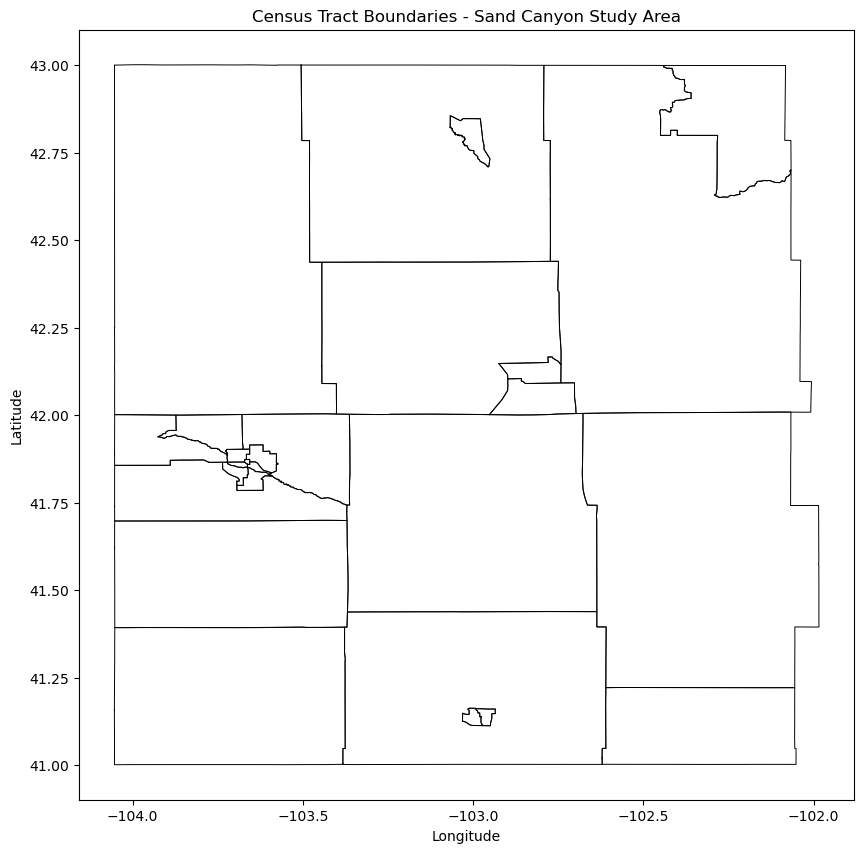

In [26]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 10))
for _, row in census_data.iterrows():
    for part in row['Boundary_Parts']:
        x = [point[0] for point in part]
        y = [point[1] for point in part]
        ax.plot(x, y, color='black', linewidth=0.7)

ax.set_title('Census Tract Boundaries - Sand Canyon Study Area')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.show()

In [27]:
print(facilities.columns)
print(facilities.head())
print(facilities.shape)

Index(['Facility_Name', 'County', 'City', 'Address', 'Longitude', 'Latitude',
       'Facility_Type'],
      dtype='object')
                                       Facility_Name     County        City  \
0  Greater Nebraska Medical & Surgical Services -...  BOX BUTTE  HEMINGFORD   
1  Greater Nebraska Medical & Surgical Services -...  BOX BUTTE    ALLIANCE   
2             LEGEND BUTTES HEALTH SERVICES - CLINIC      DAWES    CRAWFORD   
3      Sidney Regional Medical Center Walk In Clinic   CHEYENNE      SIDNEY   
4  Garden County Hospital & Nursing Home d/b/a Ga...     GARDEN     OSHKOSH   

              Address   Longitude   Latitude        Facility_Type  
0    721 CHEYENNE AVE -103.075390  42.321247  Rural Health Clinic  
1  2091 BOX BUTTE AVE -102.871338  42.115333  Rural Health Clinic  
2       11 PADDOCK ST -103.415503  42.681712  Rural Health Clinic  
3       610 GLOVER RD -102.953839  41.117699  Rural Health Clinic  
4    1100 WEST 2ND ST -102.348342  41.412545  Rural Health C

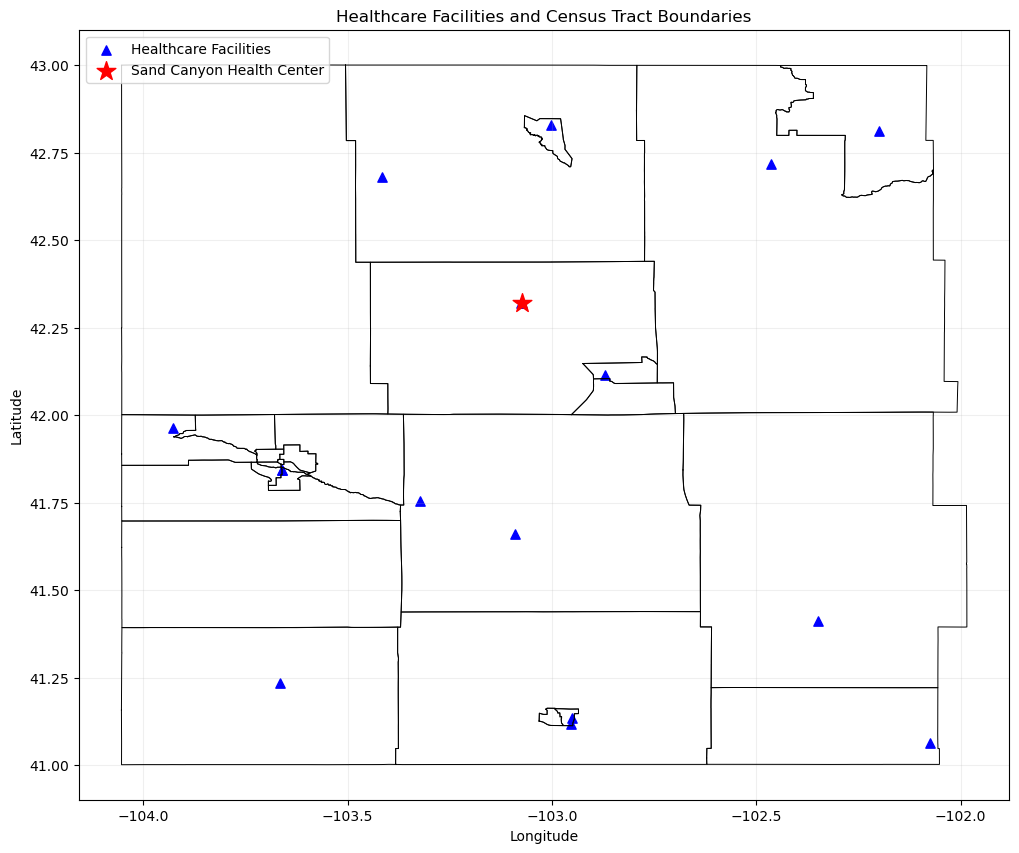

In [28]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 10))
# plotting census tract boundaries
for _, row in census_data.iterrows():
    for part in row['Boundary_Parts']:
        x = [point[0] for point in part]
        y = [point[1] for point in part]
        ax.plot(x, y, color='black', linewidth=0.7)

# plotting healthcare facilities
ax.scatter(
    facilities['Longitude'],
    facilities['Latitude'],
    color='blue',
    marker='^',
    s=45,
    label='Healthcare Facilities')

# identifying Sand Canyon!
sand_canyon = facilities[
    facilities['Facility_Name'].str.contains(
        'Sand Canyon', case=False, na=False)]
ax.scatter(
    sand_canyon['Longitude'],
    sand_canyon['Latitude'],
    color='red',
    marker='*',
    s=200,
    label='Sand Canyon Health Center',
    zorder=5)

ax.set_title('Healthcare Facilities and Census Tract Boundaries')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.legend()
ax.grid(alpha=0.2)
plt.show()

In [29]:
project_data['Tract_GEOID'] = project_data['Tract_GEOID'].astype(str)
tract_polygons_selected['GEOID'] = tract_polygons_selected['GEOID'].astype(str)

In [30]:
import shapefile
import pandas as pd

#census block shapefile
block_shapes = shapefile.Reader("tl_2026_31_tabblock20/tl_2026_31_tabblock20.shp")
block_fields = [field[0] for field in block_shapes.fields[1:]]
print(block_fields)

['STATEFP20', 'COUNTYFP20', 'TRACTCE20', 'BLOCKCE20', 'GEOID20', 'GEOIDFQ20', 'NAME20', 'MTFCC20', 'UR20', 'UACE20', 'FUNCSTAT20', 'ALAND20', 'AWATER20', 'INTPTLAT20', 'INTPTLON20', 'HOUSING20', 'POP20']


In [31]:
#census block records
block_records = block_shapes.records()
blocks = pd.DataFrame(block_records, columns=block_fields)
print(blocks.shape)
print(blocks.head())

(119103, 17)
  STATEFP20 COUNTYFP20 TRACTCE20 BLOCKCE20          GEOID20  \
0        31        055    007520      2009  310550075202009   
1        31        055    007520      2038  310550075202038   
2        31        055    007102      1022  310550071021022   
3        31        025    965700      1007  310259657001007   
4        31        057    962300      1019  310579623001019   

                  GEOIDFQ20      NAME20 MTFCC20 UR20 UACE20 FUNCSTAT20  \
0  1000000US310550075202009  Block 2009   G5040    U  65269          S   
1  1000000US310550075202038  Block 2038   G5040    U  65269          S   
2  1000000US310550071021022  Block 1022   G5040    U  65269          S   
3  1000000US310259657001007  Block 1007   G5040    R                 S   
4  1000000US310579623001019  Block 1019   G5040    R                 S   

    ALAND20  AWATER20   INTPTLAT20    INTPTLON20  HOUSING20  POP20  
0     66186       210  +41.2832823  -096.1958754         13     58  
1     75420       435  +4

In [32]:
print(blocks['POP20'].describe())
print(blocks['POP20'].sum())
print((blocks['POP20'] == 0).sum())

count    119103.000000
mean         16.468972
std          38.347256
min           0.000000
25%           0.000000
50%           5.000000
75%          16.000000
max        1633.000000
Name: POP20, dtype: float64
1961504
39324


In [33]:
# getting census tract GEOID from each block
blocks['Tract_GEOID'] = blocks['GEOID20'].astype(str).str[:11]
project_data['Tract_GEOID'] = project_data['Tract_GEOID'].astype(str).str.zfill(11)
study_tracts = project_data['Tract_GEOID'].unique()
study_blocks = blocks[blocks['Tract_GEOID'].isin(study_tracts)].copy()

print("Number of blocks:", len(study_blocks))
print("Number of tracts:", study_blocks['Tract_GEOID'].nunique())
print("Total population:", study_blocks['POP20'].sum())
print(study_blocks.head())

Number of blocks: 10258
Number of tracts: 27
Total population: 83230
    STATEFP20 COUNTYFP20 TRACTCE20 BLOCKCE20          GEOID20  \
320        31        045    950600      1155  310459506001155   
399        31        069    952100      1016  310699521001016   
421        31        123    952500      1006  311239525001006   
424        31        157    953200      2184  311579532002184   
425        31        157    953200      2131  311579532002131   

                    GEOIDFQ20      NAME20 MTFCC20 UR20 UACE20 FUNCSTAT20  \
320  1000000US310459506001155  Block 1155   G5040    R                 S   
399  1000000US310699521001016  Block 1016   G5040    R                 S   
421  1000000US311239525001006  Block 1006   G5040    R                 S   
424  1000000US311579532002184  Block 2184   G5040    R                 S   
425  1000000US311579532002131  Block 2131   G5040    R                 S   

       ALAND20  AWATER20   INTPTLAT20    INTPTLON20  HOUSING20  POP20  \
320     31

In [34]:
# block geometries
block_geometries = block_shapes.shapes()
block_polygons = pd.DataFrame({'GEOID20': [record['GEOID20'] for record in block_shapes.records()],'Geometry': [shape.points for shape in block_geometries]})
study_block_polygons = block_polygons[block_polygons['GEOID20'].isin(study_blocks['GEOID20'])].copy()

print(study_block_polygons.shape)
print(study_block_polygons.head())

(10258, 2)
             GEOID20                                           Geometry
320  310459506001155  [(-103.325489, 42.794535), (-103.32406, 42.793...
399  310699521001016  [(-102.383601, 41.977967), (-102.383503, 41.98...
421  311239525001006  [(-103.11962, 41.858011), (-103.119106, 41.858...
424  311579532002184  [(-103.947325, 41.706907), (-103.94732, 41.712...
425  311579532002131  [(-103.712746, 41.756036), (-103.712143, 41.75...


In [35]:
# combining block population data with geographic boundaries
block_map_data = study_blocks.merge(study_block_polygons,on='GEOID20',how='left')

print(block_map_data.shape)
print(block_map_data[['GEOID20', 'Tract_GEOID', 'POP20', 'Geometry']].head())
print("Missing geometries:", block_map_data['Geometry'].isna().sum())

(10258, 19)
           GEOID20  Tract_GEOID  POP20  \
0  310459506001155  31045950600      0   
1  310699521001016  31069952100      7   
2  311239525001006  31123952500     34   
3  311579532002184  31157953200      9   
4  311579532002131  31157953200      6   

                                            Geometry  
0  [(-103.325489, 42.794535), (-103.32406, 42.793...  
1  [(-102.383601, 41.977967), (-102.383503, 41.98...  
2  [(-103.11962, 41.858011), (-103.119106, 41.858...  
3  [(-103.947325, 41.706907), (-103.94732, 41.712...  
4  [(-103.712746, 41.756036), (-103.712143, 41.75...  
Missing geometries: 0


In [36]:
# summarizing block population by census tract
block_population = block_map_data.groupby('Tract_GEOID').agg(Total_Population=('POP20', 'sum'),Number_of_Blocks=('GEOID20', 'count'),Populated_Blocks=('POP20', lambda x: (x > 0).sum())).reset_index()
print(block_population)
print("Total population:", block_population['Total_Population'].sum())

    Tract_GEOID  Total_Population  Number_of_Blocks  Populated_Blocks
0   31007954000               674               180                89
1   31013951100              2217               481               285
2   31013951200              4736               251               214
3   31013951300              3889               375               294
4   31033954800              3008               917               482
5   31033954900              3714               264               222
6   31033955000              2746               167               121
7   31045950600              2634               631               321
8   31045950700              5565               336               285
9   31049955400              1838               341               224
10  31069952100              1874               316               221
11  31105954500              3434               656               379
12  31123952500              4555               963               545
13  31157952900     

In [37]:
print(facilities.shape)
print(facilities.columns)
print(facilities[['Facility_Name', 'Longitude', 'Latitude']])

(17, 7)
Index(['Facility_Name', 'County', 'City', 'Address', 'Longitude', 'Latitude',
       'Facility_Type'],
      dtype='object')
                                        Facility_Name   Longitude   Latitude
0   Greater Nebraska Medical & Surgical Services -... -103.075390  42.321247
1   Greater Nebraska Medical & Surgical Services -... -102.871338  42.115333
2              LEGEND BUTTES HEALTH SERVICES - CLINIC -103.415503  42.681712
3       Sidney Regional Medical Center Walk In Clinic -102.953839  41.117699
4   Garden County Hospital & Nursing Home d/b/a Ga... -102.348342  41.412545
5                                       GORDON CLINIC -102.200100  42.812482
6       Gordon Memorial Hospital DBA RUSHVILLE CLINIC -102.463310  42.718320
7    Sidney Regional Medical Center Physicians Clinic -102.951948  41.136077
8   KIMBALL COUNTY HOSPITAL dba Kimball Health Ser... -103.665340  41.234437
9                         CHIMNEY ROCK MEDICAL CENTER -103.324030  41.753976
10                MO

In [38]:
print(facilities.loc[0].to_string())

Facility_Name    Greater Nebraska Medical & Surgical Services -...
County                                                   BOX BUTTE
City                                                    HEMINGFORD
Address                                           721 CHEYENNE AVE
Longitude                                               -103.07539
Latitude                                                 42.321247
Facility_Type                                  Rural Health Clinic


In [39]:
import numpy as np

# getting block coordinates in radians
block_lat = np.radians(block_map_data['INTPTLAT20'].astype(float).values)
block_lon = np.radians(block_map_data['INTPTLON20'].astype(float).values)

# getting facility coordinates in radians
facility_lat = np.radians(facilities['Latitude'].values)
facility_lon = np.radians(facilities['Longitude'].values)

# calculating distances between every block and every facility
lat_diff = facility_lat[np.newaxis, :] - block_lat[:, np.newaxis]
lon_diff = facility_lon[np.newaxis, :] - block_lon[:, np.newaxis]

a = (np.sin(lat_diff / 2) ** 2 +
     np.cos(block_lat[:, np.newaxis]) *
     np.cos(facility_lat[np.newaxis, :]) *
     np.sin(lon_diff / 2) ** 2)

c = 2 * np.arcsin(np.sqrt(a))

# converting distances to miles
distance_matrix = 3958.8 * c

# nearest facility with Sand Canyon included
block_map_data['Distance_With_Sand_Canyon'] = distance_matrix.min(axis=1)

# finding and removing Sand Canyon from the facility coordinates
sand_canyon_index = facilities.index[
    facilities['Facility_Name'].str.contains('Sand Canyon', case=False)][0]

distance_matrix_without = np.delete(distance_matrix, sand_canyon_index, axis=1)

# nearest facility without Sand Canyon
block_map_data['Distance_Without_Sand_Canyon'] = distance_matrix_without.min(axis=1)

# calculating the increase in distance
block_map_data['Distance_Increase'] = (block_map_data['Distance_Without_Sand_Canyon'] - block_map_data['Distance_With_Sand_Canyon'])

print(block_map_data[['GEOID20', 'POP20','Distance_With_Sand_Canyon','Distance_Without_Sand_Canyon','Distance_Increase']].head())

           GEOID20  POP20  Distance_With_Sand_Canyon  \
0  310459506001155      0                   8.646255   
1  310699521001016      7                  32.235495   
2  311239525001006     34                  16.254171   
3  311579532002184      9                  16.768568   
4  311579532002131      6                   6.870285   

   Distance_Without_Sand_Canyon  Distance_Increase  
0                      8.646255                0.0  
1                     32.235495                0.0  
2                     16.254171                0.0  
3                     16.768568                0.0  
4                      6.870285                0.0  


In [40]:
# calculating population-weighted distances
block_map_data['Weighted_With'] = (block_map_data['Distance_With_Sand_Canyon'] * block_map_data['POP20'])

block_map_data['Weighted_Without'] = (block_map_data['Distance_Without_Sand_Canyon'] * block_map_data['POP20'])

# identifying blocks where distance increases by more than 0.01 miles
block_map_data['Affected_Population'] = np.where(block_map_data['Distance_Increase'] > 0.01,block_map_data['POP20'],0)

# summarizing access by census tract
tract_access = block_map_data.groupby('Tract_GEOID').agg(Population=('POP20', 'sum'),Weighted_With=('Weighted_With', 'sum'),Weighted_Without=('Weighted_Without', 'sum'),Affected_Population=('Affected_Population', 'sum')).reset_index()

# calculating average distances for each tract
tract_access['Avg_Distance_With'] = (tract_access['Weighted_With'] / tract_access['Population'])
tract_access['Avg_Distance_Without'] = (tract_access['Weighted_Without'] / tract_access['Population'])

tract_access['Avg_Distance_Increase'] = (tract_access['Avg_Distance_Without'] - tract_access['Avg_Distance_With'])

print(tract_access[['Tract_GEOID','Population','Avg_Distance_With','Avg_Distance_Without','Avg_Distance_Increase','Affected_Population']])
print("\nTotal population:", tract_access['Population'].sum())
print("Population affected:", tract_access['Affected_Population'].sum())

    Tract_GEOID  Population  Avg_Distance_With  Avg_Distance_Without  \
0   31007954000         674          17.751924             17.751924   
1   31013951100        2217           5.164403              5.183504   
2   31013951200        4736           0.861243              0.861243   
3   31013951300        3889           1.421354              1.421354   
4   31033954800        3008          13.179191             13.179191   
5   31033954900        3714           1.761550              1.761550   
6   31033955000        2746           1.187403              1.187403   
7   31045950600        2634           6.065390              6.068170   
8   31045950700        5565           0.673825              0.673825   
9   31049955400        1838          13.942231             13.942231   
10  31069952100        1874           7.219123              7.219123   
11  31105954500        3434           3.308689              3.308689   
12  31123952500        4555           3.362377              3.36

In [41]:
# identifying blocks where distance increases
block_map_data['Distance_Increase'] = (block_map_data['Distance_Without_Sand_Canyon'] - block_map_data['Distance_With_Sand_Canyon'])
affected_blocks = block_map_data[block_map_data['Distance_Increase'] > 0.000001]

print("Blocks with increased distance:", len(affected_blocks))
print("Population experiencing increased distance:",affected_blocks['POP20'].sum())
print("Maximum distance increase:",block_map_data['Distance_Increase'].max())
print("Population-weighted average increase:",(block_map_data['Distance_Increase'] * block_map_data['POP20']).sum()/ block_map_data['POP20'].sum())

Blocks with increased distance: 213
Population experiencing increased distance: 788
Maximum distance increase: 0.12508672147513522
Population-weighted average increase: 0.0006560565577500232
